# The 1D heat equation solved by three FD schemes

We start with the 1D heat equation:

$$\frac{\partial T}{\partial t} = \alpha\,\frac{\partial^2 T}{\partial x^2}$$

differenced in three ways: FTCS, BTCS and Crank-Nicolson. 

### Notation

$$x \to i\,, \qquad y \to j\,, \qquad z \to k\,, \qquad t \to n,$$

so the value at the $i$-th point and the $n$-th time level is $T_i^{\,n}$,
stored as `T[i, n]`. Because $k$ is the third space index, the mesh steps are
`dx` and `dt` in the code, and the diffusivity is $\alpha$, as in Tannehill:

$$r = \frac{\alpha\,\Delta t}{(\Delta x)^2}.$$

The grid, the initial and boundary conditions and the $r$ factor are set up once, below, and all 3 schemes use them.

## Set-up: grid, ICs/BCs, and the time levels to plot

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

# This is for 3D visualisation
from mpl_toolkits.mplot3d import Axes3D

### 1. Domain Definition (grid creation):

In [2]:
# Steps
dt = 0.025 # Time step -> delta_t
dx = 0.1 # Step size -> delta_x

# Diffusion coefficient:
alpha = 0.5

# Define the r factor
r_factor = alpha*dt/dx**2 #should be less than 0.5 to have stable solutions
print("r factor is:  ", r_factor) 

r factor is:   1.2499999999999998


In [3]:
# Limit for the spatial vector
a = 1.0

# Limit for the time vector
b = 0.5

# Axes
# Spatial axis
x = np.arange(0., a + dx , dx)

# Time axis, rounding it to 3 figs. is for plotting only
t = np.arange(0., b + dt , dt).round(5)

#print(x.shape)
#print(t.shape)

### 2. Set up ICs/BCs:

In [4]:
# Initial conditions
ics = np.sin(np.pi*x) # this is the initial T at t=0

# Boundary Conditions
bcs = [0., 0.] # T = 0 at x=0, and x=a

# Number of points on each axis
ni = len(x)
nt = len(t)

#print(ni, nt)

### 3. The time levels we will plot:

The same levels are used for every scheme, so the three sets of curves can be compared directly.

In [5]:
# Columns of T to draw
n_show = [0, 1, 2, 4, 8, nt - 1]

print(t[n_show])

[0.    0.025 0.05  0.1   0.2   0.5  ]


# Explicit method (Forward in Time Centered in Space method: FTCS)

It's a finite difference method where the new state depends solely on the old state. The FTCS method is based on the forward Euler method in time (hence "forward in time") and central difference in space (hence "centered in space"), giving **first-order convergence in time** and **second-order convergence in space**.

# Heat equation: 1D metal heated in the middle
$$
\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x²},
$$
$$
T_t = \alpha \, T_{xx},
$$
$\Rightarrow$ *time evaluation = constant * curvature of the function (parabolic term)*.

## Discretization
We choose **n** as the index of the *time axis* and **i** as the index of the *space axis*. 

**Forward Difference in time:**
$$
T_{t} \approx \frac{T_{i}^{\,n+1} - T_{i}^{\,n}}{\Delta t} + \mathcal{O}(\Delta t).
$$
**Central Difference in space:**
$$
T_{xx} \approx \frac{T_{i+1}^{\,n} - 2 T_{i}^{\,n} + T_{i-1}^{\,n}}{(\Delta x)^2} + \mathcal{O}((\Delta x)^2).
$$
Then,
$$
\Rightarrow \frac{T_{i}^{\,n+1} - T_{i}^{\,n}}{\Delta t} = \alpha \frac{T_{i+1}^{\,n} - 2 T_{i}^{\,n} + T_{i-1}^{\,n}}{(\Delta x)^2},
$$
$$
T_{i}^{\,n+1} - T_{i}^{\,n} = r (T_{i+1}^{\,n} - 2 T_{i}^{\,n} + T_{i-1}^{\,n}),
$$
$$
T_{i}^{\,n+1} = (1-2r)T_{i}^{\,n} + r(T_{i-1}^{\,n}+T_{i+1}^{\,n}),
$$
where
$$
r = \frac{\alpha \Delta t}{\Delta x^2}.
$$

**Stability.**

The von Neumann analysis of this scheme gives:

$$r \le \tfrac{1}{2}$$

### 1. Solution matrix, with the ICs/BCs in place:

In [6]:
# Empty matrix with the correct size
T_ftcs = np.zeros((ni, nt))

# Fill up the initial conditions
T_ftcs[:, 0] = ics

# Fill up the boundary conditions
T_ftcs[0 , :] = bcs[0]
T_ftcs[-1, :] = bcs[1]

#print(T_ftcs.round(4).T)

### 5. Fill up the inner elements of the matrix using our explicit formula:

$$T_{i}^{\,n+1} = (1-2r)T_{i}^{\,n} + r(T_{i-1}^{\,n}+T_{i+1}^{\,n})$$

In [7]:
# outer loop (time loop -> index n)

for n in range(1, nt): # From 1 as we already have the ICs

    # inner loop (spatial loop -> index i)

    for i in range(1, ni - 1): # From 1 to ni-1 as we already have the BCs set
        # Explicit formula
        T_ftcs[i, n] = (1 - 2*r_factor)*T_ftcs[i, n-1] \
                     + r_factor*(T_ftcs[i-1, n-1] + T_ftcs[i+1, n-1])

### 3. Plotting the solution for $T(x,t)$:

The rate of change depends on curvature.

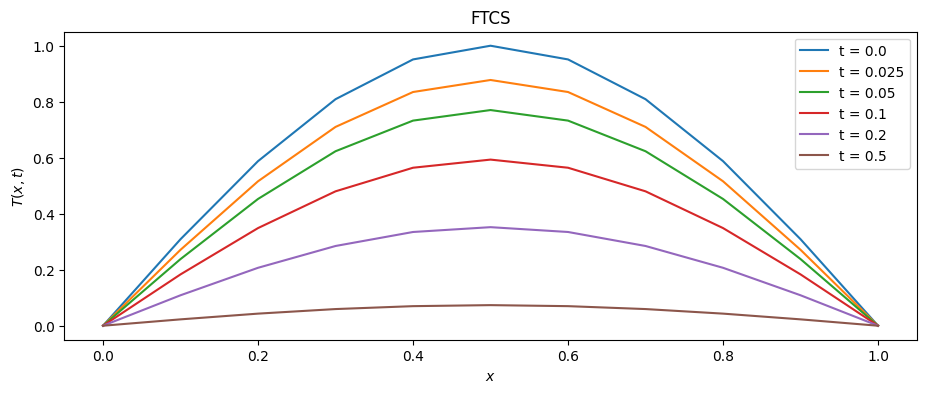

In [8]:
# Fig environment
plt.figure(figsize=(11,4))

for n in n_show:
    plt.plot(x, T_ftcs[:, n], label = f"t = {t[n]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$T(x,t)$")

plt.title("FTCS")

plt.legend()

plt.show()

# Implicit method (Backward in Time Central in Space: BTCS)

The BTCS method is an **implicit finite difference method** where the new state depends implicitly on three points at the same new time step. It is based on **backward Euler in time** and **central difference in space**, giving **first-order convergence in time** and **second-order convergence in space**. 

Unlike FTCS, BTCS is **unconditionally stable**.

# Heat equation: 1D metal heated in the middle
$$
\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}, 
\quad T_t = \alpha T_{xx},
$$
$\Rightarrow$ *time evolution = constant × curvature of the function (parabolic term)*.

## Discretization
We choose **n** as the index of the *time axis* and **i** as the index of the *space axis*. 

**Backward Difference in time:**
$$
T_t \approx \frac{T_{i}^{\,n} - T_{i}^{\,n-1}}{\Delta t} + \mathcal{O}(\Delta t),
$$
**Central Difference in space:**
$$
T_{xx} \approx \frac{T_{i+1}^{\,n} - 2 T_{i}^{\,n} + T_{i-1}^{\,n}}{\Delta x^2} + \mathcal{O}(\Delta x^2),
$$
where the spatial derivative is evaluated at the **new state** $n$.

Then,
$$
\Rightarrow \frac{T_{i}^{\,n} - T_{i}^{\,n-1}}{\Delta t} = \alpha \frac{T_{i+1}^{\,n} - 2 T_{i}^{\,n} + T_{i-1}^{\,n}}{\Delta x^2},
$$
$$
T_{i}^{\,n} - T_{i}^{\,n-1} = r \, (T_{i+1}^{\,n} - 2 T_{i}^{\,n} + T_{i-1}^{\,n}),
$$
$$
-r T_{i-1}^{\,n} + (1+2r) T_{i}^{\,n} - r T_{i+1}^{\,n} = T_{i}^{\,n-1},
$$
where
$$
r = \frac{\alpha \Delta t}{\Delta x^2}.
$$

Unlike FTCS, we need to solve a **linear system of equations** for $T_{i}^{\,n}$ at each time step.

- We get an upside-down triangle on the grid, the stencil.

- Since we are missing steps, we sweep the triangle along space so we have a closed trajectory. Then, we have a system of equations we have to solve.

- We have the same number of equations and unknowns for each time step.
  
## Matrix form
For \(N\) interior spatial points, we can write the system as:

$$
\mathbf{A} \mathbf{T}^{\,n} = \mathbf{T}^{\,n-1},
$$

where $\mathbf{T}^{\,n} = [T_{1}^{\,n}, T_{2}^{\,n}, \dots, T_{N}^{\,n}]^T$ and $\mathbf{A}$ is a tridiagonal matrix:

$$
\mathbf{A} =
\begin{bmatrix}
1+2r & -r & 0 & \dots & 0 \\
-r & 1+2r & -r & \dots & 0 \\
0 & -r & 1+2r & \dots & 0 \\
\vdots & & & \ddots & \vdots \\
0 & \dots & 0 & -r & 1+2r
\end{bmatrix}.
$$

**Stability.** 

The von Neumann analysis of this scheme indicates that it is stable for every $r$.

### 1. Solution matrix, with the ICs/BCs in place:

In [9]:
# Empty matrix with the correct size
T_btcs = np.zeros((ni, nt))

# Fill up the initial conditions
T_btcs[:, 0] = ics

# Fill up the boundary conditions
T_btcs[0 , :] = bcs[0]
T_btcs[-1, :] = bcs[1]

#print(T_btcs.round(4).T)

### 5. Fill up the inner elements of the matrix using our implicit formula:

$$(1+2r)\,T_{i}^{\,n} -r\,T_{i+1}^{\,n} - r\,T_{i-1}^{\,n} = T_{i}^{\,n-1}$$

In [10]:
# Fill up the three diagonals and add them up

D_matrix_0 = np.diag([1 + 2*r_factor]*(ni - 2),  0)
D_matrix_n = np.diag([-r_factor]*(ni - 3),      -1)
D_matrix_p = np.diag([-r_factor]*(ni - 3),      +1)

D_matrix = D_matrix_0 + D_matrix_n + D_matrix_p

#print(D_matrix)

### 6. Solve the linear system of eqs:

In [11]:
# Loop over the time axis:

# Iteration over each time step, each column of the matrix
for n in range(1, nt):

    # Create b vector using the (n-1) column, make a safe copy
    b = T_btcs[1:-1, n-1].copy()

    # Add the BCs
    b[0]  = b[0]  + r_factor*T_btcs[0, n]
    b[-1] = b[-1] + r_factor*T_btcs[-1, n]

    # The solution for n
    sln_unknown = np.linalg.solve(D_matrix, b)

    T_btcs[1:-1, n] = sln_unknown

#print(T_btcs.T)

### 4. Plotting the solution for $T(x,t)$:

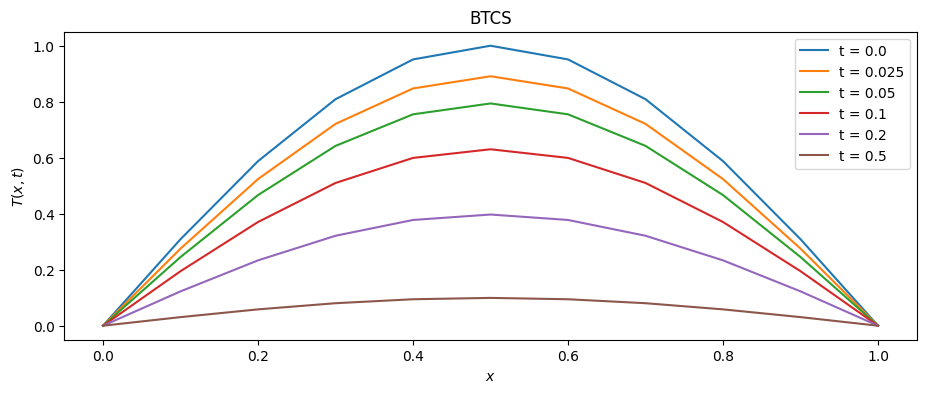

In [12]:
# Fig environment
plt.figure(figsize=(11,4))

for n in n_show:
    plt.plot(x, T_btcs[:, n], label = f"t = {t[n]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$T(x,t)$")

plt.title("BTCS")

plt.legend()

plt.show()

# Crank Nicolson method

We start off with the heat equation:


$$\frac{\partial u}{\partial t}=\alpha\frac{\partial^2 u}{\partial x^2}$$

which we discretise as follows:

$$\frac{u_{i}^{\,n+1}-u_{i}^{\,n}}{\Delta t}=\frac{\alpha}{2}\left(\frac{u_{i+1}^{\,n}-2u_{i}^{\,n}+u_{i-1}^{\,n}}{(\Delta x)^2}+\frac{u_{i+1}^{\,n+1}-2u_{i}^{\,n+1}+u_{i-1}^{\,n+1}}{(\Delta x)^2}\right)$$

This is a second-order in time discretization, where the RHS has been centred in time.

### The r-factor:

$$r=\frac{k\,\alpha}{(\Delta x)^2}$$

### Implicit-explicit form:

$$2u_{i}^{\,n+1}-r\left(u_{i+1}^{\,n+1}-2u_{i}^{\,n+1}+u_{i-1}^{\,n+1}\right)=2u_{i}^{\,n}+r\left(u_{i+1}^{\,n}-2u_{i}^{\,n}+u_{i-1}^{\,n}\right)$$

$$\Rightarrow -r\,u_{i+1}^{\,n+1}+2u_{i}^{\,n+1}(1+r)-r\,u_{i-1}^{\,n+1}=r\,u_{i+1}^{\,n}+2(1-r)u_{i}^{\,n}+r\,u_{i-1}^{\,n}$$


As we can see, we are using 6 points.


### In matrix form:

$$
\begin{bmatrix}
2(1+r) & -r & 0\cdots \\
-r & 2(1+r) & 0\cdots \\
\cdots & \cdots & \cdots \\
\cdots & \cdots & -r \\
0 & -r & 2(1+r)\cdots \\
\end{bmatrix}
\begin{bmatrix}
\cdots \\
u_{i-1}^{\,n+1} \\
u_{i}^{\,n+1} \\
u_{i+1}^{\,n+1} \\
\cdots \\
\end{bmatrix}=
\begin{bmatrix}
2(1-r) & r & 0\cdots \\
r & 2(1-r) & 0\cdots \\
\cdots & \cdots & \cdots \\
\cdots & \cdots & r \\
0 & r & 2(1-r)\cdots \\
\end{bmatrix}
\begin{bmatrix}
\cdots \\
u_{i-1}^{\,n} \\
u_{i}^{\,n} \\
u_{i+1}^{\,n} \\
\cdots \\
\end{bmatrix}+
\begin{bmatrix}
r(u_{0,0}+u_{0,1}) \\
\cdots \\
0 \\
\cdots \\
r(u_{n,0}+u_{n,1}) \\
\end{bmatrix}
$$

### 1. Solution matrix, with the ICs/BCs in place:

In [13]:
# Empty matrix with the correct size
T_cn = np.zeros((ni, nt))

# Fill up the initial conditions
T_cn[:, 0] = ics

# Fill up the boundary conditions
T_cn[0 , :] = bcs[0]
T_cn[-1, :] = bcs[1]

#print(T_cn.round(4).T)

### 5. Fill up the inner elements of the first matrix ($D_1$):

### In matrix form:

$$D_1=
\begin{bmatrix}
2(1+r) & -r & 0\cdots \\
-r & 2(1+r) & 0\cdots \\
\cdots & \cdots & \cdots \\
\cdots & \cdots & -r \\
0 & -r & 2(1+r)\cdots \\
\end{bmatrix}
$$

In [14]:
# Fill up the three diagonals of D1 and add them up

D1_matrix_0 = np.diag([2 + 2*r_factor]*(ni - 2),  0)
D1_matrix_n = np.diag([-r_factor]*(ni - 3),      -1)
D1_matrix_p = np.diag([-r_factor]*(ni - 3),      +1)

D1_matrix = D1_matrix_0 + D1_matrix_n + D1_matrix_p

#print(D1_matrix)

### 5. Fill up the inner elements of the second matrix ($D_2$):

### In matrix form:

$$
D_2=\begin{bmatrix}
2(1-r) & r & 0\cdots \\
r & 2(1-r) & 0\cdots \\
\cdots & \cdots & \cdots \\
\cdots & \cdots & r \\
0 & r & 2(1-r)\cdots \\
\end{bmatrix}
$$

In [15]:
# Same process for D2

D2_matrix_0 = np.diag([2 - 2*r_factor]*(ni - 2),  0)
D2_matrix_n = np.diag([r_factor]*(ni - 3),       -1)
D2_matrix_p = np.diag([r_factor]*(ni - 3),       +1)

D2_matrix = D2_matrix_0 + D2_matrix_n + D2_matrix_p

#print(D2_matrix)

### 6. Create the b vector (vector of known values):

#### Solve the linear system of eqs:

E.g. from the ICs.

$$
\begin{bmatrix}
2(1-r) & r & 0\cdots \\
r & 2(1-r) & 0\cdots \\
\cdots & \cdots & \cdots \\
\cdots & \cdots & r \\
0 & r & 2(1-r)\cdots \\
\end{bmatrix}
\begin{bmatrix}
\cdots \\
u_{i-1}^{\,n} \\
u_{i}^{\,n} \\
u_{i+1}^{\,n} \\
\cdots \\
\end{bmatrix}+
\begin{bmatrix}
r(u_{0,0}+u_{0,1}) \\
\cdots \\
0 \\
\cdots \\
r(u_{n,0}+u_{n,1}) \\
\end{bmatrix}
$$

In [16]:
for n in range(0, nt - 1):

    # Known values at level n
    b = T_cn[1:-1, n].copy()

    # Evaluate RHS
    b = np.dot(D2_matrix, b)
    # b = D2_matrix@b (another option)

    # Append missing values
    b[0]  = b[0]  + r_factor*(T_cn[0, n+1]  + T_cn[0, n])
    b[-1] = b[-1] + r_factor*(T_cn[-1, n+1] + T_cn[-1, n])

    # Compute the solution vector:
    sln_b = np.linalg.solve(D1_matrix, b)

    # Update T matrix
    T_cn[1:-1, n+1] = sln_b

#print(T_cn.T)

### 4. Plotting the solution for $T(x,t)$:

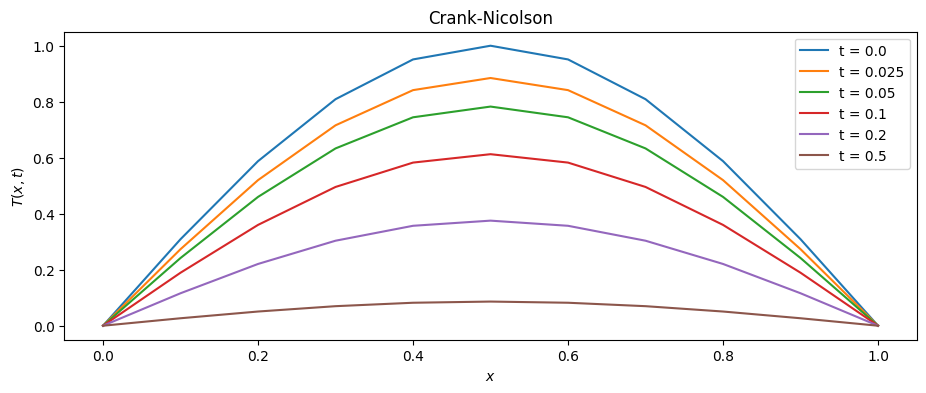

In [17]:
# Fig environment
plt.figure(figsize=(11,4))

for n in n_show:
    plt.plot(x, T_cn[:, n], label = f"t = {t[n]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$T(x,t)$")

plt.title("Crank-Nicolson")

plt.legend()

plt.show()

# Comparing the 3 schemes

The three solutions were computed on the same grid, from the same ICs/BCs and
with the same $r$, so they can be put side by side.

In [18]:
# The three solutions, in one list for the comparison plots
slns  = [T_ftcs, T_btcs, T_cn]
names = ["FTCS", "BTCS", "Crank-Nicolson"]

#### A. Temperature vs. position, scheme by scheme:

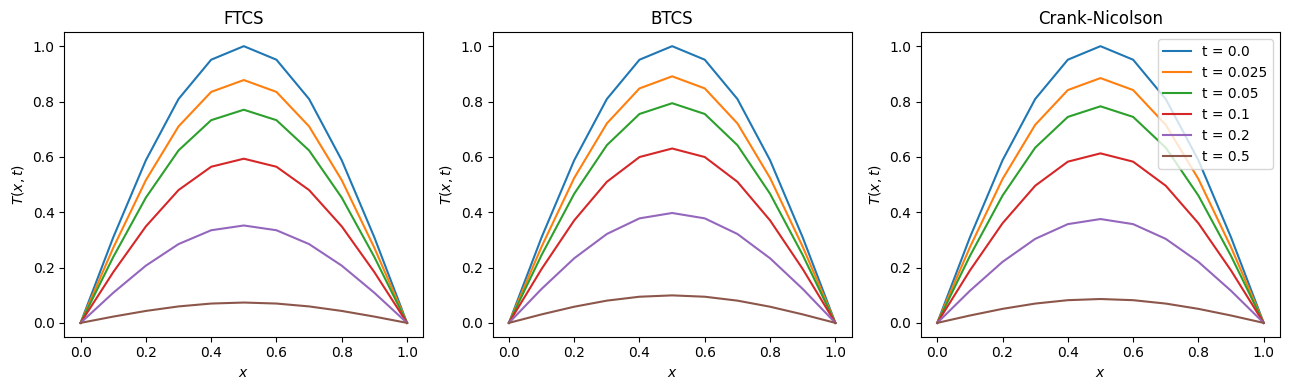

In [19]:
plt.figure(figsize=(13,4))

for k in range(3):

    plt.subplot(1, 3, k + 1)

    for n in n_show:
        plt.plot(x, slns[k][:, n], label = f"t = {t[n]}")

    plt.xlabel(r"$x$")
    plt.ylabel(r"$T(x,t)$")
    plt.title(names[k])
    plt.ylim(-0.05, 1.05)

plt.legend()

plt.tight_layout()

plt.show()

#### B. Temperature surface projection:

In [20]:
# Create 2D grid using meshgrid
x_grid, t_grid = np.meshgrid(x, t)

#print(x_grid.shape, t_grid.shape, T_ftcs.T.shape)

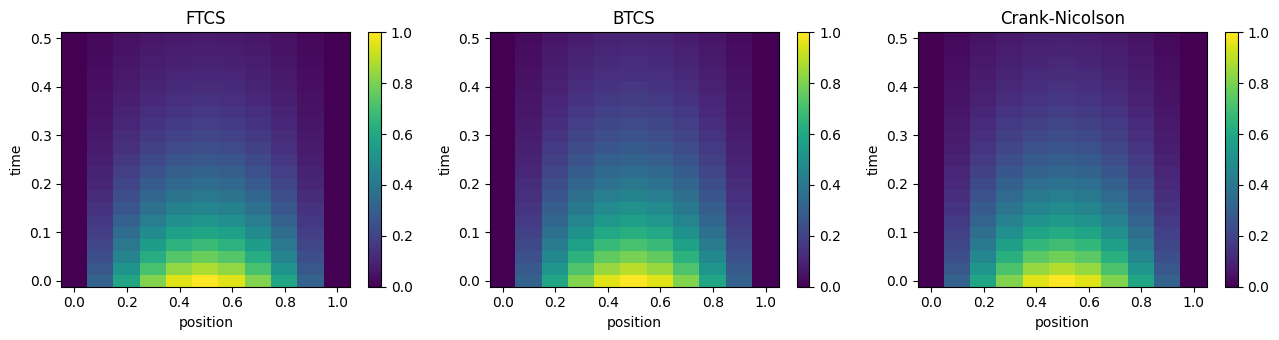

In [21]:
plt.figure(figsize=(13,3.5))

for k in range(3):

    plt.subplot(1, 3, k + 1)

    z_temp = plt.pcolor(x_grid, t_grid, slns[k].T, cmap = 'viridis',
                        vmin = 0., vmax = 1.)

    plt.xlabel("position")
    plt.ylabel("time")
    plt.title(names[k])

    plt.colorbar(z_temp)

plt.tight_layout()

plt.show()

# When the explicit method goes unstable

Of the three schemes only FTCS has a stringent condition attached to it:

$$ r = \frac{\alpha\,\Delta t}{(\Delta x)^2} \le \frac{1}{2}. $$

BTCS and Crank-Nicolson are **unconditionally stable**: there is no condition on $r$ at all, so this section concerns the explicit march only.

The mode that goes first is the sawtooth, $+1, -1, +1, \dots$ from one point to the next. For it the amplification factor is

$$ G = 1 - 4r\sin^{2}\tfrac{\beta}{2} \;\Big|_{\beta = \pi} \;=\; 1 - 4r, $$

so above $r = 1/2$ its modulus exceeds one and it is multiplied by $|1-4r|$ at every single step.

### Values to try, with `dx = 0.1` and `alpha = 0.5`

| `dt` | r | growth per step | behaviour |
|------|------|------|------|
| 0.009 | 0.45 | 0.8 | stable |
| 0.010 | 0.50 | 1.0 | exactly at the limit |
| 0.015 | 0.75 | 2.0 | unstable: doubles every step |
| 0.025 | 1.25 | 4.0 | unstable, and it is the `dt` used above |

The last row is worth staring at. 

Notice that the code above already runs above the limit, and the curves still look perfectly sensible. They do, because the sawtooth is not in the initial condition: $\sin(\pi x)$ contains none of it, so the mode is seeded only by round-off, at about $10^{-16}$. Growing by a factor of 4 per step it needs some 27 steps to reach $O(1)$, and we took 20.

Carry the same march on to $t = 1$ instead of $t = 0.5$ and it arrives.

In [23]:
# The explicit limit is r <= 1/2. What each dt gives, with dx = 0.1 and alpha = 0.5:

for dt_try in [0.009, 0.010, 0.015, 0.025]:

    r_try = alpha*dt_try/dx**2

    print("dt =", dt_try, "  r =", round(r_try, 3),
          "  growth per step =", round(abs(1 - 4*r_try), 3))

dt = 0.009   r = 0.45   growth per step = 0.8
dt = 0.01   r = 0.5   growth per step = 1.0
dt = 0.015   r = 0.75   growth per step = 2.0
dt = 0.025   r = 1.25   growth per step = 4.0


### The same march, carried on to $t = 1$

Everything below is the explicit code from the top of the notebook, with the
same `dx`, `alpha` and `dt` and only the end time changed. Uncomment and run
it to watch the sawtooth take over.

In [31]:
# Same dx, same alpha, same dt: only the end time changes

t_bad = np.arange(0., 1.0 + dt , dt)

nt_bad = len(t_bad)

print("r factor is:  ", r_factor, "   steps:", nt_bad)

r factor is:   1.2499999999999998    steps: 41


In [35]:
# Empty matrix with the correct size
T_bad = np.zeros((ni, nt_bad))

# Fill up the initial conditions
T_bad[:, 0] = ics

# Fill up the boundary conditions
T_bad[0 , :] = bcs[0]
T_bad[-1, :] = bcs[1]

# outer loop (time loop -> index n)
for n in range(1, nt_bad):

    # inner loop (spatial loop -> index i)
    for i in range(1, ni - 1):
        # Explicit formula
        T_bad[i, n] = (1 - 2*r_factor)*T_bad[i, n-1] + r_factor*(T_bad[i-1, n-1] + T_bad[i+1, n-1])

# A. Solution profiles

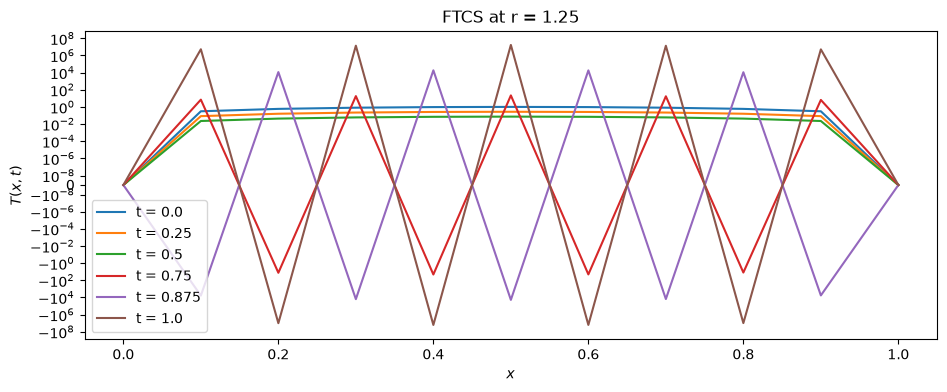

In [36]:
#    both show up on the same plot

plt.figure(figsize=(11,4))

for n in [0, 10, 20, 30, 35, nt_bad - 1]:
    plt.plot(x, T_bad[:, n], label = f"t = {t_bad[n]}")

plt.yscale("symlog", linthresh=1e-8)

plt.xlabel(r"$x$")
plt.ylabel(r"$T(x,t)$")

plt.title("FTCS at r = 1.25")

plt.legend()

plt.show()